# ADD tuning: refreshed assignment results

This report repeats the paired one-sided Wilcoxon procedure from
`LinearAssignmentReport.ipynb` and `QuadraticAssignmentReport.ipynb` for the new
cluster results. The original notebooks and their historical outputs are retained.

All three strategies and all four weights are evaluated against the newly computed
Best Cost baseline: Mixed and GDF at 0.1, 0.2, 0.3, 0.4; Weighted Rank at
0.1, 0.35, 0.5, 0.7. Each objective has 250 paired training tasks (n=12,...,16,
50 per size). This notebook reads saved outcomes; it never runs the optimizers.

For minimization, improvement is `(BestCost - ADD) / abs(BestCost) * 100`.
All displayed percentages use one decimal place; calculations and CSV exports
retain full precision. Raw p-values reproduce the old procedure. Holm-adjusted
p-values are added for 12 tests per objective and, more conservatively, all 24 tests.


In [1]:
using Pkg
root = isfile("../Project.toml") ? abspath("..") : abspath(".")
Pkg.activate(root)
ENV["GKSwstype"] = "100"
include(joinpath(root, "scripts", "report_ADD_tuning.jl"))
report = analyze_add()
display(MIME"text/html"(), Markdown.parse(read(joinpath(report.output, "audit.md"), String)))

LINEAR rankings:

  Activating project at `D:\Releases\OhMyU1_public`



gdf w=0.4: mean=6.9%, median=5.9%, W/T/L=235/14/1, p=9.48673859335271e-41, Holm24=2.1819498764711233e-39
gdf w=0.3: mean=6.5%, median=6.0%, W/T/L=239/10/1, p=2.348242745641565e-41, Holm24=5.6357825895397564e-40
gdf w=0.2: mean=5.8%, median=5.1%, W/T/L=232/18/0, p=4.127202923710015e-40, Holm24=9.079846432162033e-39
weighted_rank w=0.35: mean=5.6%, median=5.0%, W/T/L=222/21/7, p=6.829081170016489e-39, Holm24=1.3658162340032976e-37
weighted_rank w=0.5: mean=5.5%, median=5.0%, W/T/L=227/15/8, p=1.6730211948092205e-39, Holm24=3.513344509099363e-38
weighted_rank w=0.7: mean=4.9%, median=4.2%, W/T/L=225/18/7, p=1.5432468745280672e-38, Holm24=2.9321690616033276e-37
gdf w=0.1: mean=4.3%, median=3.7%, W/T/L=214/33/3, p=1.6276338514743216e-37, Holm24=2.9297409326537788e-36
mixed w=0.4: mean=2.8%, median=2.4%, W/T/L=189/38/23, p=2.438200527524405e-26, Holm24=3.4134807385341673e-25
mixed w=0.3: mean=2.1%, median=1.7%, W/T/L=178/36/36, p=4.683425939640276e-19, Holm24=4.683425939640276e-18
weighted_

Input audit 
 Source: data\assignment_add_tuning_v1\1f4c7d9256d7 . Recorded implementation: 1f4c7d9256d722e04683982cb5d6d25781a403f746f03e257e1134f56d91638e . 
 
 Linear : 250 Best Cost and 3,000 ADD outcomes; all expected keys present; objective/input hashes, initial-data hashes, seeds, initial costs, feasibility, final costs and 20 completed iterations verified. 
 
 Quadratic : 250 Best Cost and 3,000 ADD outcomes; all expected keys present; objective/input hashes, initial-data hashes, seeds, initial costs, feasibility, final costs and 20 completed iterations verified. 
 
 
 All 6500 outcomes are complete. The runner explicitly schedules Best Cost as array task 0, once per training instance and objective (500 baseline runs total). There are 6,000 ADD runs. No test data, old result files or optimization reruns enter this report. 
 Recorded solver parameters: (NUM_FEASIBLE_SAMPLES = 1000, NUM_MPS_SAMPLES = 10000, LINK_DEGENERACY = 1, NUM_SWEEP_ITER = 1, NUM_GLOBAL_ITER = 20, LEARNING_RATE = 0.05, UTILITY_FRACTION = 0.05, KEEP_NUM_WORST = 0.0) . Both families use 1,000 initial feasible points, 10,000 MPS samples, 20 global iterations, one sweep, learning rate 0.05, elite fraction 0.05, and no worst retention. The runner disables EELS and the barrier. ADD and Best Cost both receive external feasible samples; this is the ADD comparison, not the closed-data EELS comparison.

In [2]:
include(joinpath(root, "scripts", "plot_ADD_tuning.jl"))

plot_add_selected (generic function with 1 method)

In [3]:
display(MIME"text/html"(), Markdown.parse(read(joinpath(report.output, "linear_table.md"), String)))

Strategy,Weight,W / T / L,Win rate,Mean improvement,Median improvement,W statistic,One-sided p,Holm (12),Holm (24)
GDF,0.4,235 / 14 / 1,94.0%,6.9%,5.9%,27963.0,9.49e-41,1.04e-39,2.18e-39
GDF,0.3,239 / 10 / 1,95.6%,6.5%,6.0%,28908.0,2.35e-41,2.82e-40,5.64e-40
GDF,0.2,232 / 18 / 0,92.8%,5.8%,5.1%,27028.0,4.13e-40,4.13e-39,9.08e-39
Weighted Rank,0.35,222 / 21 / 7,88.8%,5.6%,5.0%,26207.0,6.83e-39,5.46e-38,1.37e-37
Weighted Rank,0.5,227 / 15 / 8,90.8%,5.5%,5.0%,27531.0,1.67e-39,1.51e-38,3.51e-38
Weighted Rank,0.7,225 / 18 / 7,90.0%,4.9%,4.2%,26746.0,1.54e-38,1.08e-37,2.93e-37
GDF,0.1,214 / 33 / 3,85.6%,4.3%,3.7%,23630.0,1.63e-37,9.77e-37,2.93e-36
Mixed,0.4,189 / 38 / 23,75.6%,2.8%,2.4%,20727.0,2.44e-26,1.22e-25,3.41e-25
Mixed,0.3,178 / 36 / 36,71.2%,2.1%,1.7%,19522.0,4.68e-19,1.41e-18,4.68e-18
Weighted Rank,0.1,157 / 74 / 19,62.8%,2.0%,1.2%,14457.0,3.38e-23,1.35e-22,4.05e-22


Boxplots show 50 paired relative improvements per size, with the ordinary
1.5-IQR whisker rule and outliers. Group medians and group averages are computed
from exactly the same 50 points as each box. The horizontal zero line is parity
with Best Cost. All 12 configurations within this objective share y limits,
chosen to include all observations without clipping.

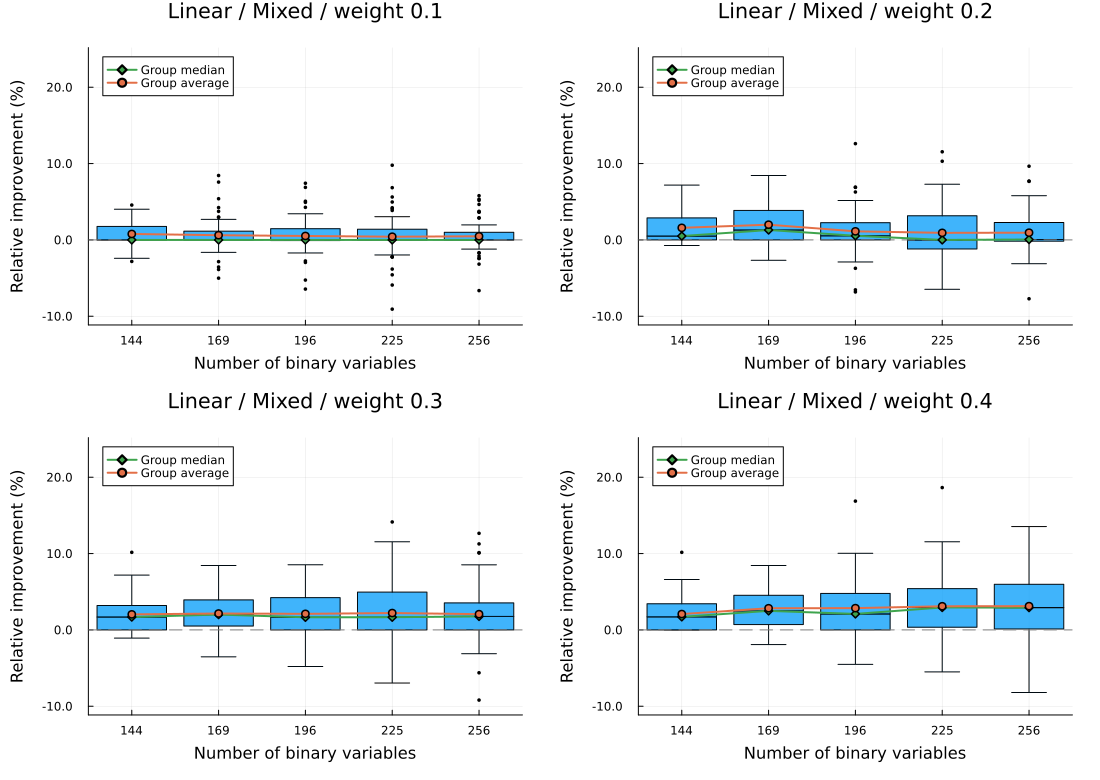

In [4]:
display(plot_add_weights(report, "linear", "mixed"))

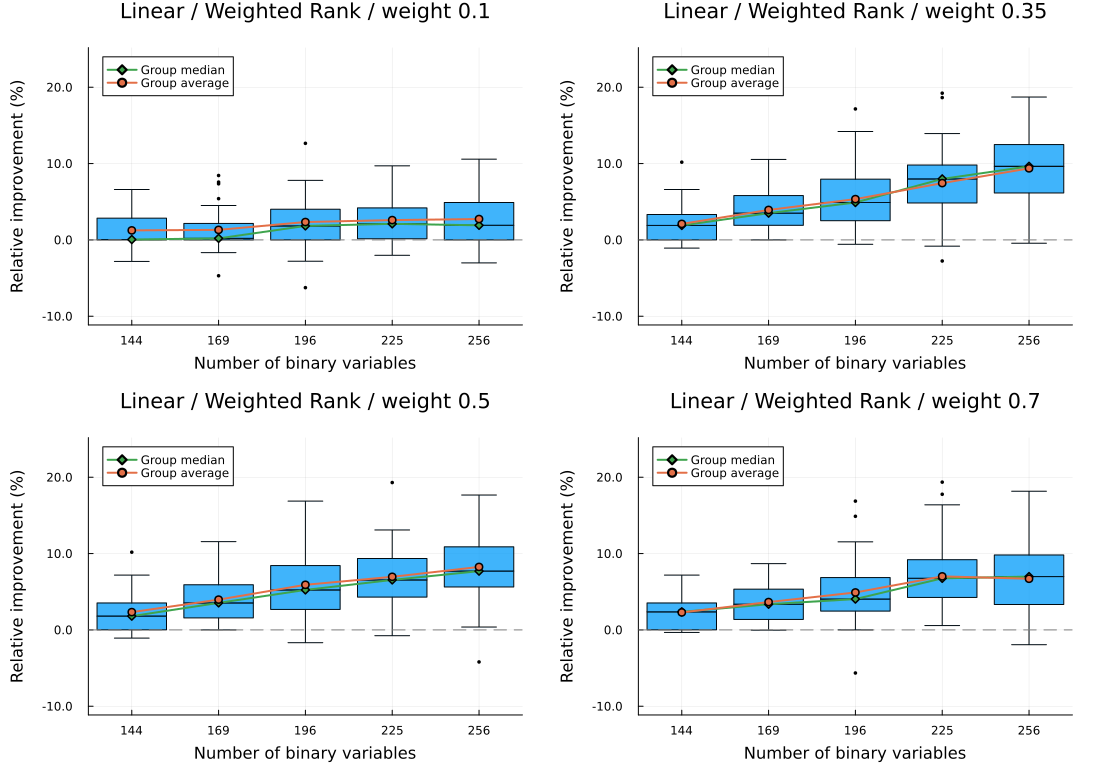

In [5]:
display(plot_add_weights(report, "linear", "weighted_rank"))

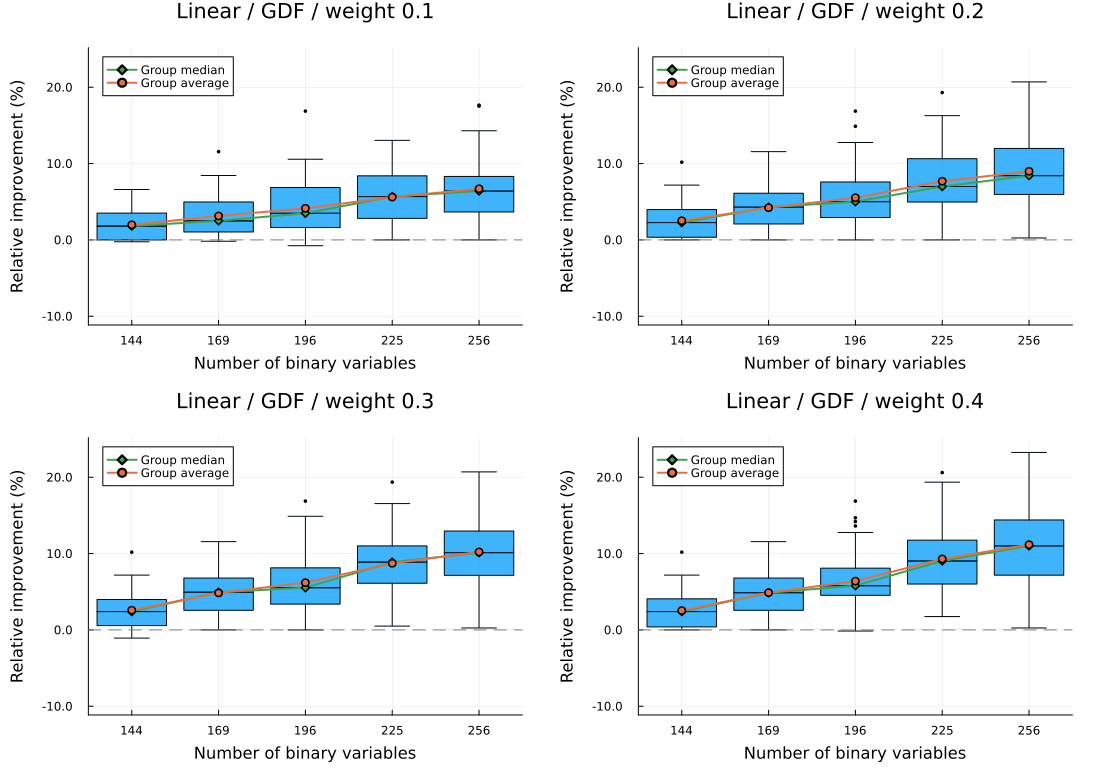

In [6]:
display(plot_add_weights(report, "linear", "gdf"))

In [7]:
display(MIME"text/html"(), Markdown.parse(read(joinpath(report.output, "quadratic_table.md"), String)))

Strategy,Weight,W / T / L,Win rate,Mean improvement,Median improvement,W statistic,One-sided p,Holm (12),Holm (24)
GDF,0.4,209 / 26 / 15,83.6%,6.6%,6.2%,24425.0,2.05e-34,2.46e-33,3.49e-33
GDF,0.3,197 / 33 / 20,78.8%,5.9%,5.4%,22423.0,1.27e-30,1.40e-29,2.04e-29
Weighted Rank,0.35,189 / 28 / 33,75.6%,5.9%,5.4%,22988.0,8.27e-29,8.27e-28,1.24e-27
Weighted Rank,0.5,184 / 23 / 43,73.6%,5.2%,4.2%,22510.0,2.19e-22,1.75e-21,2.41e-21
GDF,0.2,179 / 44 / 27,71.6%,4.6%,3.5%,19655.0,4.35e-26,3.91e-25,5.65e-25
Weighted Rank,0.7,151 / 28 / 71,60.4%,3.5%,2.0%,19289.0,2.71e-13,1.63e-12,2.17e-12
Mixed,0.4,165 / 35 / 50,66.0%,2.7%,1.8%,18031.0,1.03e-12,5.14e-12,7.20e-12
GDF,0.1,145 / 73 / 32,58.0%,2.5%,1.1%,13019.0,2.49e-14,1.75e-13,2.24e-13
Mixed,0.3,140 / 45 / 65,56.0%,2.1%,1.3%,15044.0,6.63e-08,1.99e-07,2.65e-07
Weighted Rank,0.1,137 / 71 / 42,54.8%,1.9%,0.5%,12589.0,3.28e-11,1.31e-10,1.97e-10


Boxplots show 50 paired relative improvements per size, with the ordinary
1.5-IQR whisker rule and outliers. Group medians and group averages are computed
from exactly the same 50 points as each box. The horizontal zero line is parity
with Best Cost. All 12 configurations within this objective share y limits,
chosen to include all observations without clipping.

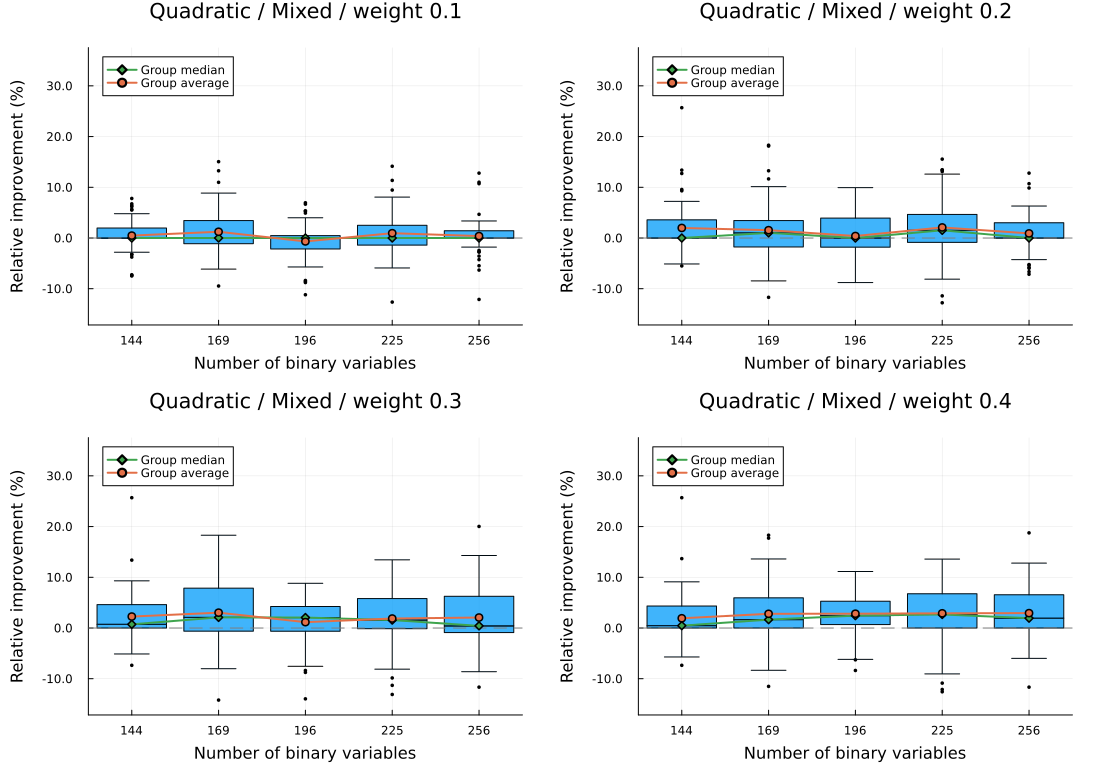

In [8]:
display(plot_add_weights(report, "quadratic", "mixed"))

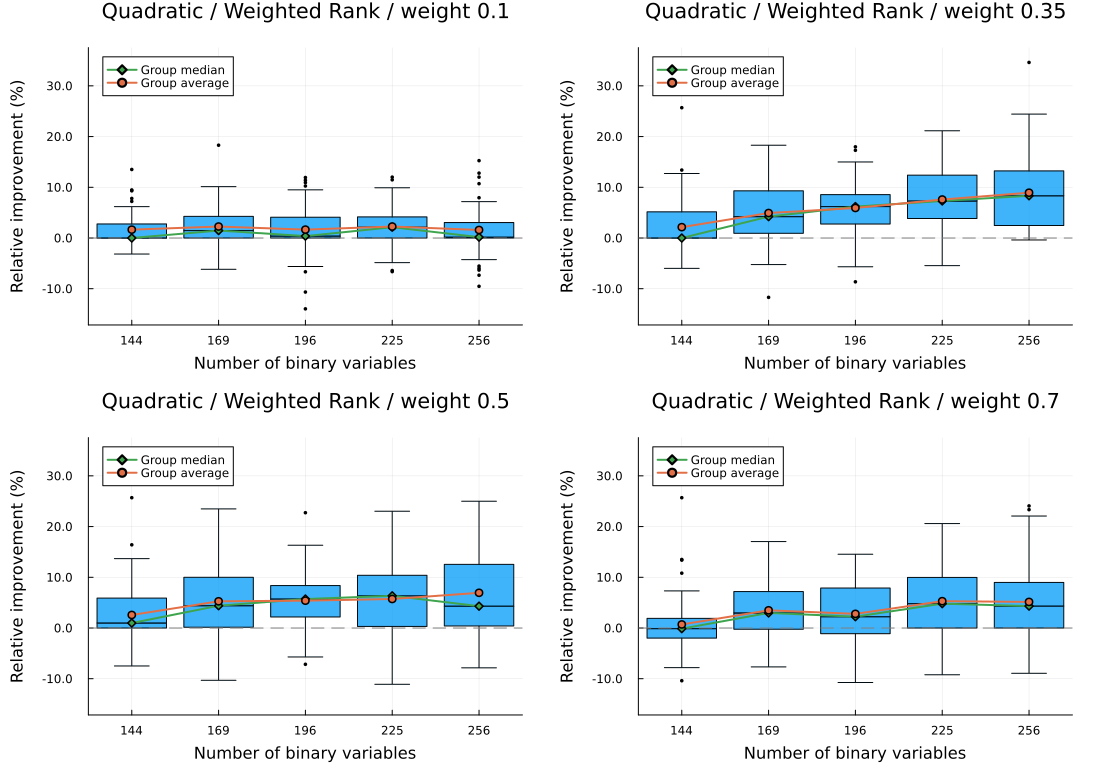

In [9]:
display(plot_add_weights(report, "quadratic", "weighted_rank"))

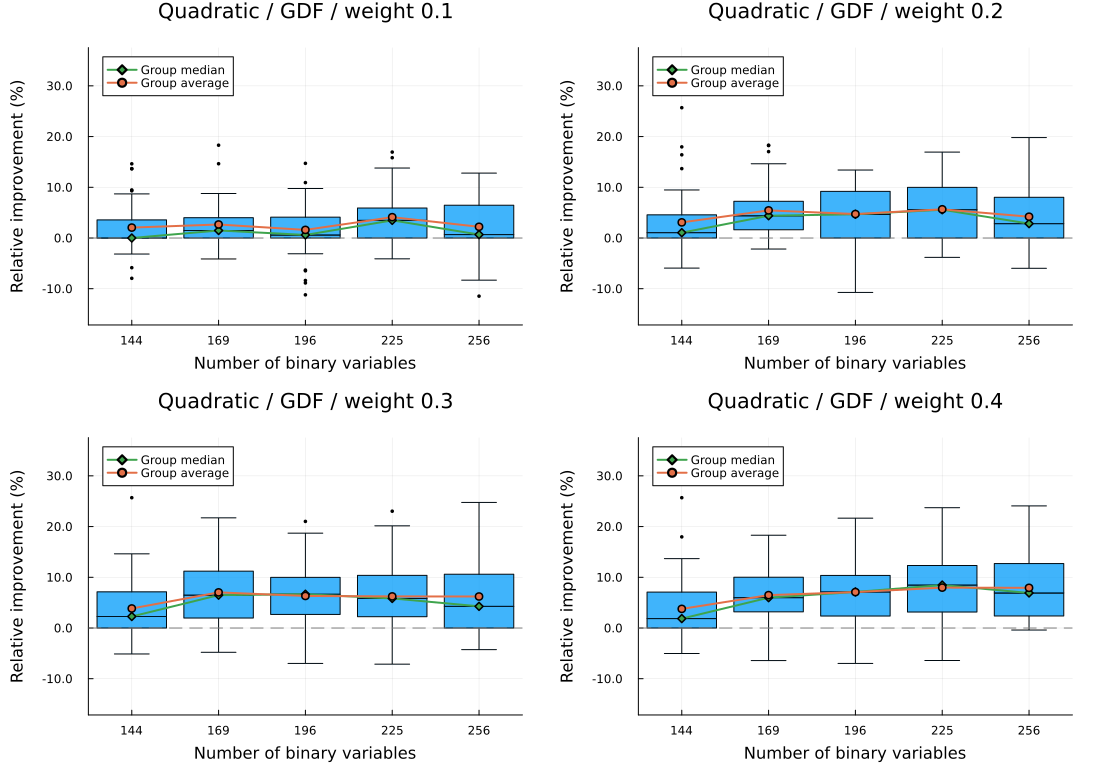

In [10]:
display(plot_add_weights(report, "quadratic", "gdf"))

In [11]:
display(MIME"text/html"(), Markdown.parse(read(joinpath(report.output, "recommendations.md"), String)))

Objective,Best weight within strategy,Weight,Mean improvement,Median improvement,W / T / L
Linear,Mixed,0.4,2.8%,2.4%,189 / 38 / 23
Linear,Weighted Rank,0.35,5.6%,5.0%,222 / 21 / 7
Linear,GDF,0.4,6.9%,5.9%,235 / 14 / 1
Quadratic,Mixed,0.4,2.7%,1.8%,165 / 35 / 50
Quadratic,Weighted Rank,0.35,5.9%,5.4%,189 / 28 / 33
Quadratic,GDF,0.4,6.6%,6.2%,209 / 26 / 15
Objective,Competitor,Weight,Selected W / T / L,Two-sided p,Holm (66)
Linear,Mixed,0.4,199 / 42 / 9,2.68e-34,1.45e-32
Linear,Weighted Rank,0.35,143 / 66 / 41,2.94e-15,7.64e-14
Linear,GDF,0.3,90 / 102 / 58,0.0013,0.0066


## Selected configurations: relative and absolute improvement

As in the original notebooks, both relative and absolute cost differences are
shown for the selected configurations. The median and average overlays refer to
each size group separately. Scales in this selected summary adapt to each panel;
use the preceding figures to compare hyperparameters on common scales. Absolute
panels retain the original reports' 1.0-IQR whiskers; relative panels use 1.5 IQR.

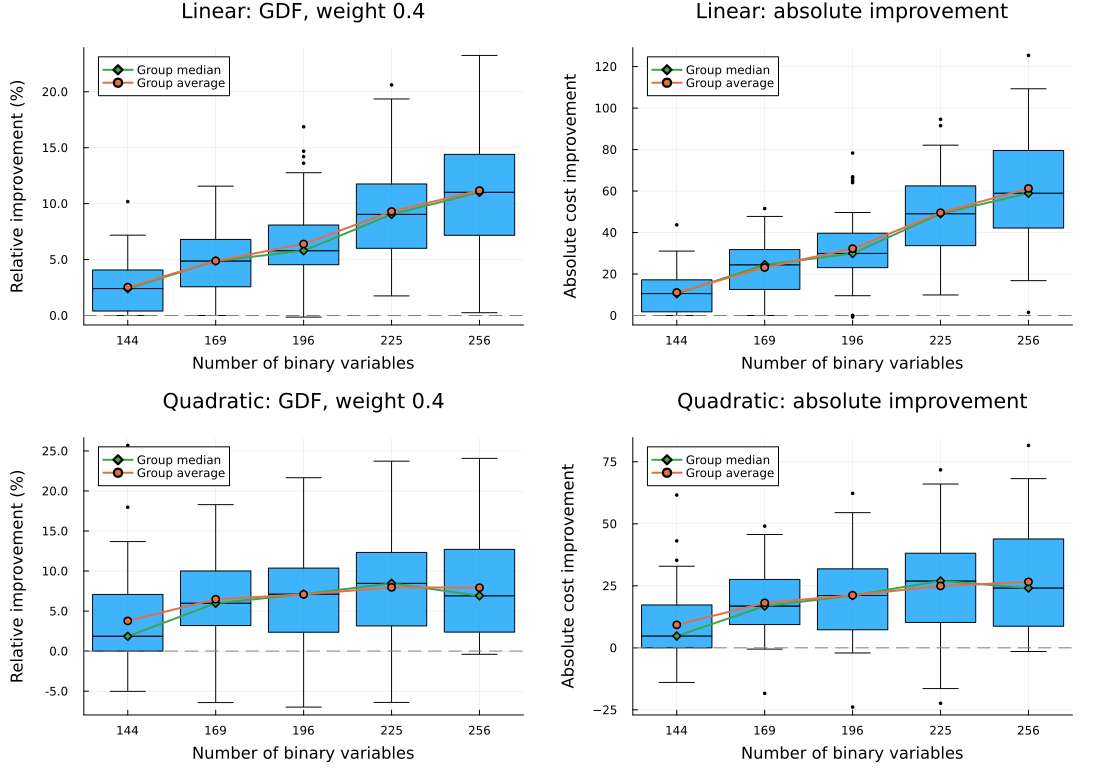

In [12]:
display(plot_add_selected(report))

## Reproducibility and exported artifacts

`add_tuning_analysis/` contains the full configuration table, every size-level
comparison, all 66 pairwise configuration comparisons per objective, all paired
costs, source result-file SHA-256 hashes, audit and recommendation text, and PDF/PNG
figures. The analysis is implemented in `scripts/report_ADD_tuning.jl`, plots in
`scripts/plot_ADD_tuning.jl`, and this notebook is generated by
`scripts/build_ADD_tuning_notebook.py`. Run all cells to regenerate the analysis.

The choice is made on **training/tuning data only**. A separate test-set evaluation
must follow before claiming generalization; this notebook does not inspect test
outcomes or modify the article or cluster runner.